# Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import os
import time
import warnings

warnings.filterwarnings("ignore")

# Config

In [2]:
BASE = "."
SRC = os.path.join(BASE, "src")

# Dataset creditcard.csv tidak diunggah ke repositori (>100 MB).
# Notebook mencari berkas pada beberapa lokasi berikut.
CANDIDATES = [
    "creditcard.csv",
    os.path.join("..", "ensemble-imbalance", "creditcard.csv"),
]
CACHED_FILE = next((p for p in CANDIDATES if os.path.exists(p)), None)
assert CACHED_FILE is not None, "creditcard.csv tidak ditemukan."

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5

os.makedirs(SRC, exist_ok=True)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

sns.set_theme(style="whitegrid")

# Dataframe Generation

In [3]:
df = pd.read_csv(os.path.join(BASE, CACHED_FILE))
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.shape

(284807, 31)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

| Atribut | Tipe Atribut | Penjelasan |
|---|---|---|
| `Time` | Numerik kontinu | Selisih waktu dalam detik dari transaksi pertama. Bukan besaran yang bermakna langsung, sehingga diturunkan menjadi fitur jam. |
| `V1`--`V28` | Numerik kontinu | Hasil transformasi PCA dari atribut asli yang dirahasiakan untuk menjaga privasi pemegang kartu. |
| `Amount` | Numerik kontinu | Nilai transaksi dalam satuan mata uang. Memiliki skala jauh lebih besar dibanding `V1`--`V28`. |
| `Class` | Nominal biner | Label target. `0` = transaksi normal, `1` = transaksi penipuan (_fraud_). |

# EDA

## Distribusi Kelas

In [6]:
class_count = df["Class"].value_counts().sort_index()
class_pct = (df["Class"].value_counts(normalize=True).sort_index() * 100).round(4)

pd.DataFrame({
    "jumlah": class_count,
    "persentase (%)": class_pct,
})

,jumlah,persentase (%)
Class,,
0,284315,99.8273
1,492,0.1727


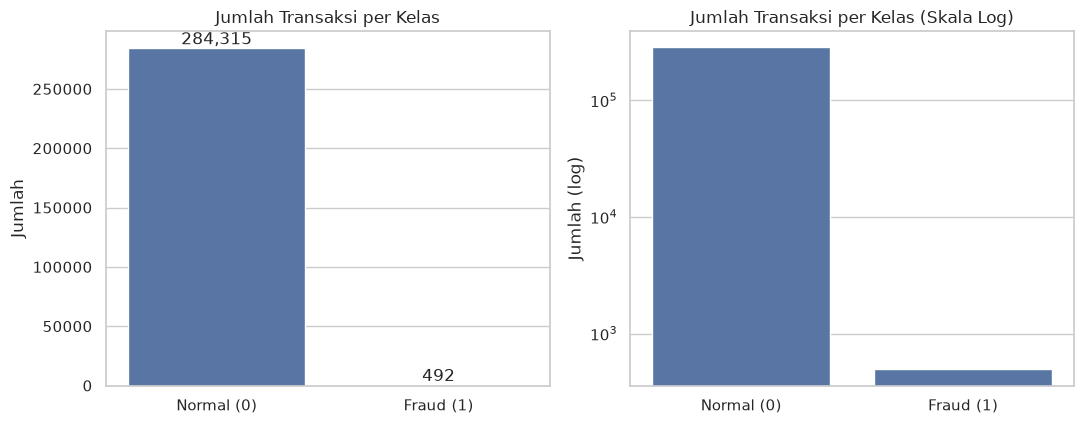

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

sns.barplot(x=["Normal (0)", "Fraud (1)"], y=class_count.values, ax=axes[0])
axes[0].set_title("Jumlah Transaksi per Kelas")
axes[0].set_ylabel("Jumlah")
for i, v in enumerate(class_count.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

sns.barplot(x=["Normal (0)", "Fraud (1)"], y=class_count.values, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Jumlah Transaksi per Kelas (Skala Log)")
axes[1].set_ylabel("Jumlah (log)")

plt.tight_layout()
plt.savefig(os.path.join(SRC, "class_distribution.png"), dpi=150)
plt.show()

Distribusi kelas sangat tidak seimbang. Dari 284.807 transaksi, hanya 492 transaksi (0,1727%) yang merupakan penipuan, sedangkan 284.315 transaksi (99,8273%) adalah transaksi normal. Rasio antara kelas mayoritas dan minoritas mencapai sekitar 578:1.

Kondisi ini membuat model yang selalu memprediksi kelas mayoritas tetap memperoleh akurasi di atas 99%, tetapi sama sekali tidak mampu mendeteksi penipuan. Oleh karena itu, akurasi tidak dapat dijadikan metrik utama dan penanganan _class imbalance_ menjadi langkah yang wajib dilakukan.

## Statistik Deskriptif

In [8]:
df[["Time", "Amount", "Class"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


In [9]:
df.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


## Time dan Amount

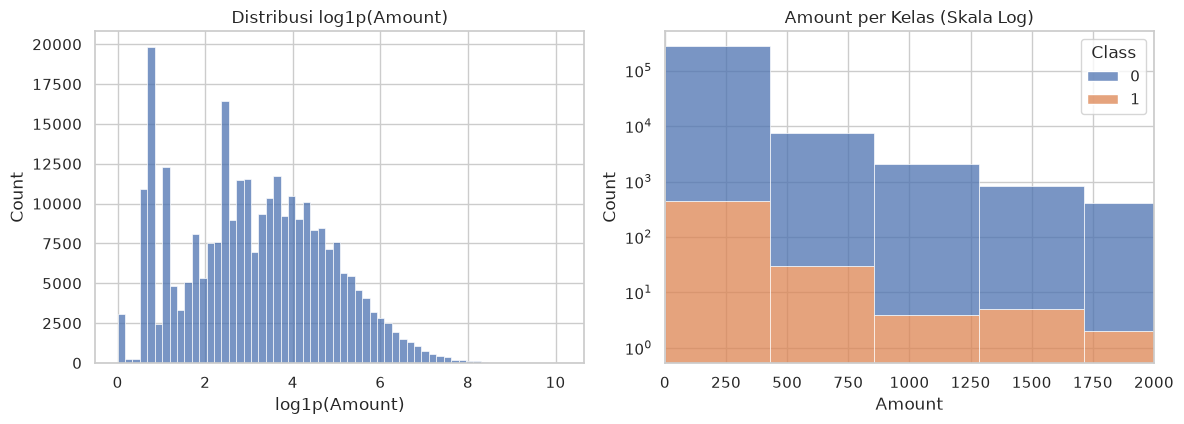

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

sns.histplot(np.log1p(df["Amount"]), bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribusi log1p(Amount)")
axes[0].set_xlabel("log1p(Amount)")

sns.histplot(df, x="Amount", hue="Class", bins=60, ax=axes[1], multiple="stack")
axes[1].set_yscale("log")
axes[1].set_title("Amount per Kelas (Skala Log)")
axes[1].set_xlim(0, 2000)

plt.tight_layout()
plt.savefig(os.path.join(SRC, "amount_distribution.png"), dpi=150)
plt.show()

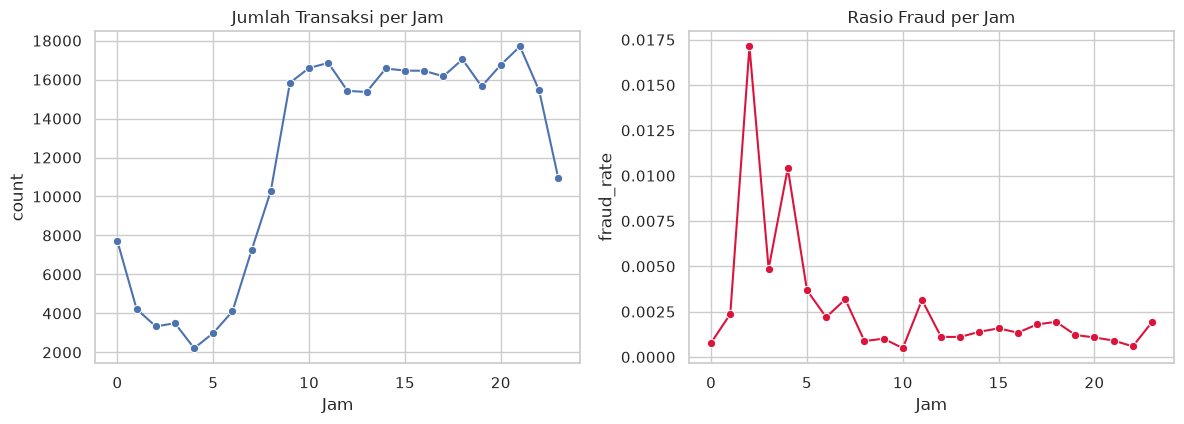

In [11]:
df["Hour"] = (df["Time"] // 3600) % 24

hourly = df.groupby("Hour")["Class"].agg(["count", "sum"])
hourly["fraud_rate"] = hourly["sum"] / hourly["count"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

sns.lineplot(x=hourly.index, y=hourly["count"], marker="o", ax=axes[0])
axes[0].set_title("Jumlah Transaksi per Jam")
axes[0].set_xlabel("Jam")

sns.lineplot(x=hourly.index, y=hourly["fraud_rate"], marker="o", color="crimson", ax=axes[1])
axes[1].set_title("Rasio Fraud per Jam")
axes[1].set_xlabel("Jam")

plt.tight_layout()
plt.savefig(os.path.join(SRC, "fraud_by_hour.png"), dpi=150)
plt.show()

Distribusi `Amount` sangat menceng ke kanan, dengan sebagian besar transaksi bernilai kecil tetapi terdapat sejumlah transaksi bernilai sangat besar. Transaksi penipuan cenderung terkonsentrasi pada nilai yang relatif kecil, walaupun terdapat beberapa penipuan bernilai besar.

Dari sisi waktu, jumlah transaksi mengikuti pola harian dengan aktivitas terendah pada dini hari. Menariknya, rasio penipuan justru meningkat pada jam-jam dengan volume transaksi rendah, terutama sekitar pukul 02.00--05.00. Pola ini menunjukkan bahwa `Time` menyimpan informasi yang relevan dan lebih berguna ketika diturunkan menjadi fitur jam.

## Korelasi Fitur terhadap Kelas

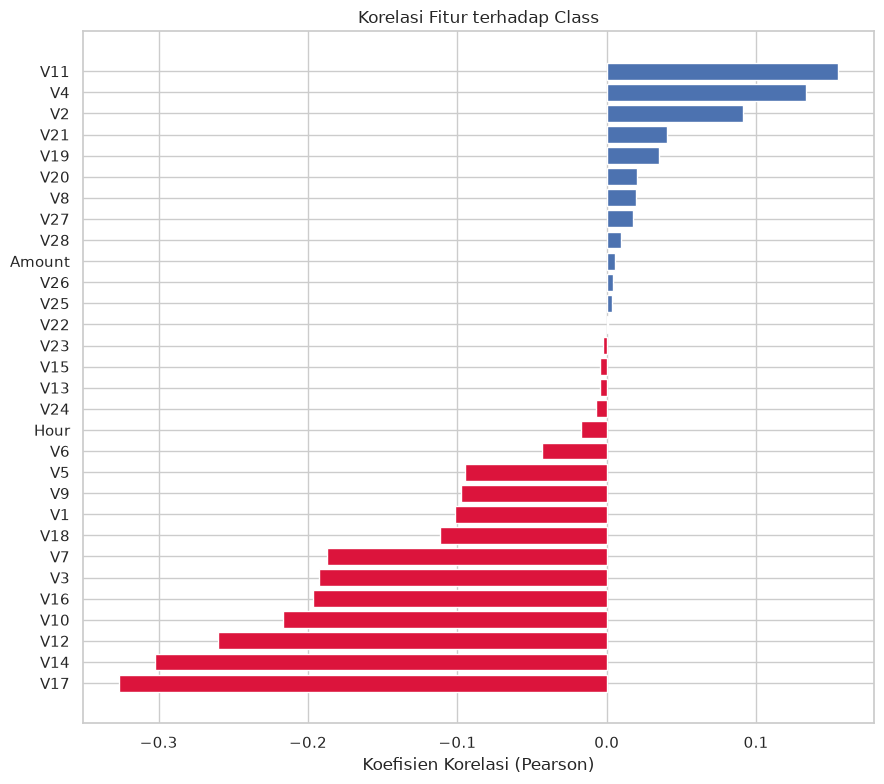

In [12]:
corr_class = df.drop(columns=["Time"]).corr(numeric_only=True)["Class"].drop("Class")
corr_class = corr_class.sort_values()

fig, ax = plt.subplots(figsize=(9, 8))
colors = ["crimson" if v < 0 else "#4C72B0" for v in corr_class.values]
ax.barh(corr_class.index, corr_class.values, color=colors)
ax.set_title("Korelasi Fitur terhadap Class")
ax.set_xlabel("Koefisien Korelasi (Pearson)")

plt.tight_layout()
plt.savefig(os.path.join(SRC, "corr_class.png"), dpi=150)
plt.show()

Beberapa komponen PCA memiliki korelasi yang cukup kuat terhadap kelas target. `V17`, `V14`, `V12`, dan `V10` berkorelasi negatif, sedangkan `V11`, `V4`, dan `V2` berkorelasi positif. Fitur `Amount` hanya memiliki korelasi yang sangat lemah terhadap kelas, sehingga nilai transaksi saja tidak cukup untuk membedakan penipuan.

Karena fitur `V1`--`V28` merupakan hasil PCA, fitur-fitur ini saling ortogonal dan tidak memiliki korelasi antar-fitur. Hal ini menjelaskan mengapa banyak fitur tetap perlu dipertahankan dalam pemodelan.

# Praproses

## Penskalaan Amount

In [13]:
scaler = StandardScaler()
df["Amount_scaled"] = scaler.fit_transform(df[["Amount"]])

df = df.drop(columns=["Amount", "Time"])
df[["Amount_scaled", "Hour", "Class"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Amount_scaled,284807.0,-3.672378e-17,1.000002,-0.353229,-0.33084,-0.265271,-0.044717,102.362243
Hour,284807.0,1.404647e+01,5.835854,0.000000,10.00000,15.000000,19.000000,23.000000
Class,284807.0,1.727486e-03,0.041527,0.000000,0.00000,0.000000,0.000000,1.000000


Fitur `Amount` distandarisasi menggunakan _z-score_ agar skalanya sebanding dengan `V1`--`V28` yang telah dinormalisasi oleh PCA. Fitur `Time` diubah menjadi fitur `Hour` karena nilai detik mentah tidak bermakna langsung bagi model. Atribut asli `Time` dan `Amount` kemudian dihapus untuk menghindari redundansi.

Dataset tidak memiliki nilai hilang sehingga tidak diperlukan imputasi.

## Pembagian Data Latih dan Uji

In [14]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)
print("Fraud pada latih:", int(y_train.sum()), f"({y_train.mean() * 100:.4f}%)")
print("Fraud pada uji  :", int(y_test.sum()), f"({y_test.mean() * 100:.4f}%)")

Data latih: (227845, 30)
Data uji  : (56962, 30)
Fraud pada latih: 394 (0.1729%)
Fraud pada uji  : 98 (0.1720%)


Pembagian data menggunakan `stratify=y` agar proporsi kelas pada data latih dan data uji tetap sama dengan distribusi aslinya. Data uji tidak pernah disentuh oleh proses resampling sehingga tetap merepresentasikan kondisi dunia nyata, yaitu dengan rasio penipuan yang sangat kecil.

# Penanganan Class Imbalance

In [15]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

rus = RandomUnderSampler(random_state=RANDOM_STATE)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)

summary = pd.DataFrame({
    "Asli": pd.Series(y_train).value_counts().sort_index(),
    "SMOTE": pd.Series(y_train_smote).value_counts().sort_index(),
    "Undersampling": pd.Series(y_train_rus).value_counts().sort_index(),
})
summary.index = ["Normal (0)", "Fraud (1)"]
summary

,Asli,SMOTE,Undersampling
Normal (0),227451,227451,394
Fraud (1),394,227451,394


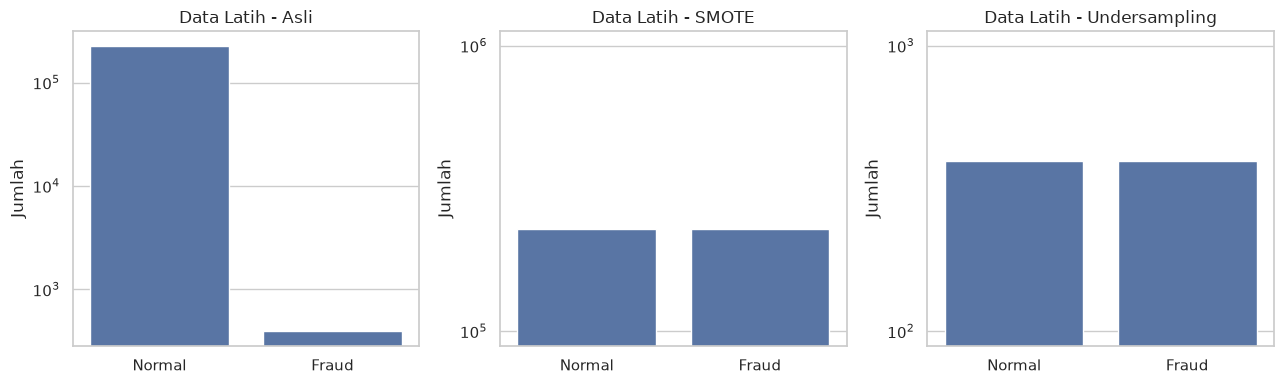

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (title, yy) in zip(
    axes,
    [("Asli", y_train), ("SMOTE", y_train_smote), ("Undersampling", y_train_rus)],
):
    counts = pd.Series(yy).value_counts().sort_index()
    sns.barplot(x=["Normal", "Fraud"], y=counts.values, ax=ax)
    ax.set_title(f"Data Latih - {title}")
    ax.set_ylabel("Jumlah")
    ax.set_yscale("log")

plt.tight_layout()
plt.savefig(os.path.join(SRC, "resampling.png"), dpi=150)
plt.show()

Tiga pendekatan penanganan _class imbalance_ digunakan:

- **SMOTE** (_oversampling_) membangkitkan sampel sintetis pada kelas minoritas dengan interpolasi antar tetangga terdekat, sehingga kelas fraud menjadi seimbang dengan kelas normal tanpa menduplikasi data. Pendekatan ini mempertahankan seluruh informasi kelas mayoritas.
- **Undersampling** mengurangi kelas mayoritas dengan membuang sebagian transaksi normal hingga jumlahnya seimbang dengan kelas fraud. Data menjadi jauh lebih kecil sehingga pelatihan lebih cepat, tetapi berisiko membuang informasi yang berguna.
- **Cost-sensitive learning** (bobot kelas) tidak mengubah data, melainkan memberikan penalti lebih besar pada kesalahan klasifikasi kelas minoritas melalui parameter `class_weight`.

Resampling hanya diterapkan pada data latih. Data uji tetap menggunakan distribusi asli agar evaluasi mencerminkan performa model pada kondisi nyata.

# Membangun Model

Seluruh model yang dibandingkan pada praktikum ini merupakan _ensemble_ pada level model, yaitu model yang menggabungkan banyak model dasar di dalam proses pelatihannya. Dua keluarga utama digunakan sesuai ketentuan praktikum, kemudian ditambahkan tiga implementasi _gradient boosting_ modern sebagai pembanding:

- **Random Forest**, yaitu _bagging_ yang membangun banyak pohon keputusan pada sampel _bootstrap_ dan menggabungkan hasilnya melalui _voting_.
- **Gradient Boosting** (`HistGradientBoostingClassifier`), yaitu _boosting_ yang membangun pohon secara berurutan untuk memperbaiki kesalahan model sebelumnya.
- **CatBoost, XGBoost, dan LightGBM**, yaitu tiga implementasi _gradient boosting_ modern yang memiliki mekanisme penanganan _class imbalance_ bawaan.

Setiap keluarga _ensemble_ diuji pada empat konfigurasi: baseline tanpa penanganan, _class weighting_ (cost-sensitive), SMOTE, dan undersampling. Seluruh model dievaluasi pada data uji yang sama agar perbandingannya adil.

## Fungsi Evaluasi

In [17]:
def evaluate(name, model, X_test, y_test):
    proba = model.predict_proba(X_test)[:, 1]
    y_pred = (proba >= 0.5).astype(int)

    return {
        "Model": name,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, proba),
        "AUC-PR": average_precision_score(y_test, proba),
    }

In [18]:
results = []
fitted = {}
curves = {}
preds = {}


def run(name, model, X_tr, y_tr):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    elapsed = time.time() - t0

    row = evaluate(name, model, X_test, y_test)
    row["Waktu (s)"] = round(elapsed, 1)

    results.append(row)
    fitted[name] = model
    curves[name] = model.predict_proba(X_test)[:, 1]
    preds[name] = (curves[name] >= 0.5).astype(int)

    print(f"{name:34s} {elapsed:7.1f}s | F1={row['F1']:.4f} | AUC-PR={row['AUC-PR']:.4f}")
    return model

## Ensemble Inti: Random Forest dan Gradient Boosting

In [19]:
rf_params = dict(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)

run("Random Forest (Baseline)", RandomForestClassifier(**rf_params), X_train, y_train)
run("Random Forest (class_weight)", RandomForestClassifier(class_weight="balanced", **rf_params), X_train, y_train)
run("Random Forest (SMOTE)", RandomForestClassifier(**rf_params), X_train_smote, y_train_smote)
run("Random Forest (Undersampling)", RandomForestClassifier(**rf_params), X_train_rus, y_train_rus)

Random Forest (Baseline)              73.8s | F1=0.8681 | AUC-PR=0.8584


Random Forest (class_weight)          29.3s | F1=0.8525 | AUC-PR=0.8663


Random Forest (SMOTE)                133.9s | F1=0.8333 | AUC-PR=0.8679


Random Forest (Undersampling)          0.5s | F1=0.0822 | AUC-PR=0.6909


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [20]:
hgb_params = dict(max_iter=300, learning_rate=0.1, random_state=RANDOM_STATE)

run("Gradient Boosting (Baseline)", HistGradientBoostingClassifier(**hgb_params), X_train, y_train)
run("Gradient Boosting (class_weight)", HistGradientBoostingClassifier(class_weight="balanced", **hgb_params), X_train, y_train)
run("Gradient Boosting (SMOTE)", HistGradientBoostingClassifier(**hgb_params), X_train_smote, y_train_smote)
run("Gradient Boosting (Undersampling)", HistGradientBoostingClassifier(**hgb_params), X_train_rus, y_train_rus)

Gradient Boosting (Baseline)           0.7s | F1=0.5780 | AUC-PR=0.4721


Gradient Boosting (class_weight)       0.9s | F1=0.4619 | AUC-PR=0.7343


Gradient Boosting (SMOTE)              4.3s | F1=0.7446 | AUC-PR=0.8172


Gradient Boosting (Undersampling)      0.6s | F1=0.0638 | AUC-PR=0.6547


,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",300
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing val

## Boosting Modern: CatBoost, XGBoost, dan LightGBM

In [21]:
SCALE_POS_WEIGHT = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"scale_pos_weight = {SCALE_POS_WEIGHT:.2f}")

scale_pos_weight = 577.29


In [22]:
run(
    "CatBoost (balanced)",
    CatBoostClassifier(
        iterations=300, depth=6, auto_class_weights="Balanced",
        random_seed=RANDOM_STATE, thread_count=-1, verbose=0, allow_writing_files=False,
    ),
    X_train, y_train,
)

run(
    "XGBoost (scale_pos_weight)",
    XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=6, tree_method="hist",
        scale_pos_weight=SCALE_POS_WEIGHT, n_jobs=-1, random_state=RANDOM_STATE,
        eval_metric="aucpr",
    ),
    X_train, y_train,
)

run(
    "LightGBM (balanced)",
    LGBMClassifier(
        n_estimators=300, learning_rate=0.1, num_leaves=31, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE, verbose=-1,
    ),
    X_train, y_train,
)

CatBoost (balanced)                    7.2s | F1=0.7742 | AUC-PR=0.8626


XGBoost (scale_pos_weight)             6.3s | F1=0.8646 | AUC-PR=0.8847


LightGBM (balanced)                    5.5s | F1=0.8649 | AUC-PR=0.8677


,n_estimators,300
,class_weight,'balanced'
,random_state,42
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,subsample_for_bin,200000
,objective,None


Ketiga implementasi _boosting_ modern menunjukkan performa yang kuat tanpa perlu resampling. XGBoost dengan `scale_pos_weight` menjadi model tunggal terbaik, sedangkan LightGBM dan CatBoost berada sedikit di bawahnya. Ketiganya menangani ketidakseimbangan melalui mekanisme internal, yaitu pembobotan gradien pada fungsi objektif, sehingga tidak memerlukan pembangkitan data sintetis maupun pengurangan data.

Perbedaan utama ketiganya terletak pada strategi penanganan _imbalance_:

- **XGBoost** menggunakan `scale_pos_weight`, yang mengalikan gradien kelas minoritas sehingga kesalahan pada kelas fraud dianggap lebih mahal.
- **LightGBM** menggunakan `class_weight="balanced"`, yang memberikan bobot berbanding terbalik dengan frekuensi kelas pada perhitungan gradien.
- **CatBoost** menggunakan `auto_class_weights="Balanced"`, yang menyeimbangkan bobot kelas secara otomatis selama pelatihan.

Ketiganya juga memiliki mekanisme pengendalian kompleksitas model, seperti regularisasi L2, pembatasan kedalaman pohon, dan _subsampling_ fitur, sehingga mampu menekan _overfitting_ pada data yang sangat tidak seimbang.

# Evaluasi Model

## Perbandingan Metrik

In [23]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Precision,Recall,F1,AUC-ROC,AUC-PR,Waktu (s)
Model,,,,,,
Random Forest (Baseline),0.9405,0.8061,0.8681,0.9619,0.8584,73.8
Random Forest (class_weight),0.9176,0.7959,0.8525,0.9608,0.8663,29.3
Random Forest (SMOTE),0.8511,0.8163,0.8333,0.9750,0.8679,133.9
Random Forest (Undersampling),0.0430,0.9184,0.0822,0.9780,0.6909,0.5
Gradient Boosting (Baseline),0.5250,0.6429,0.5780,0.7258,0.4721,0.7
Gradient Boosting (class_weight),0.3110,0.8980,0.4619,0.9497,0.7343,0.9
Gradient Boosting (SMOTE),0.6466,0.8776,0.7446,0.9572,0.8172,4.3
Gradient Boosting (Undersampling),0.0331,0.9184,0.0638,0.9750,0.6547,0.6
CatBoost (balanced),0.7059,0.8571,0.7742,0.9683,0.8626,7.2


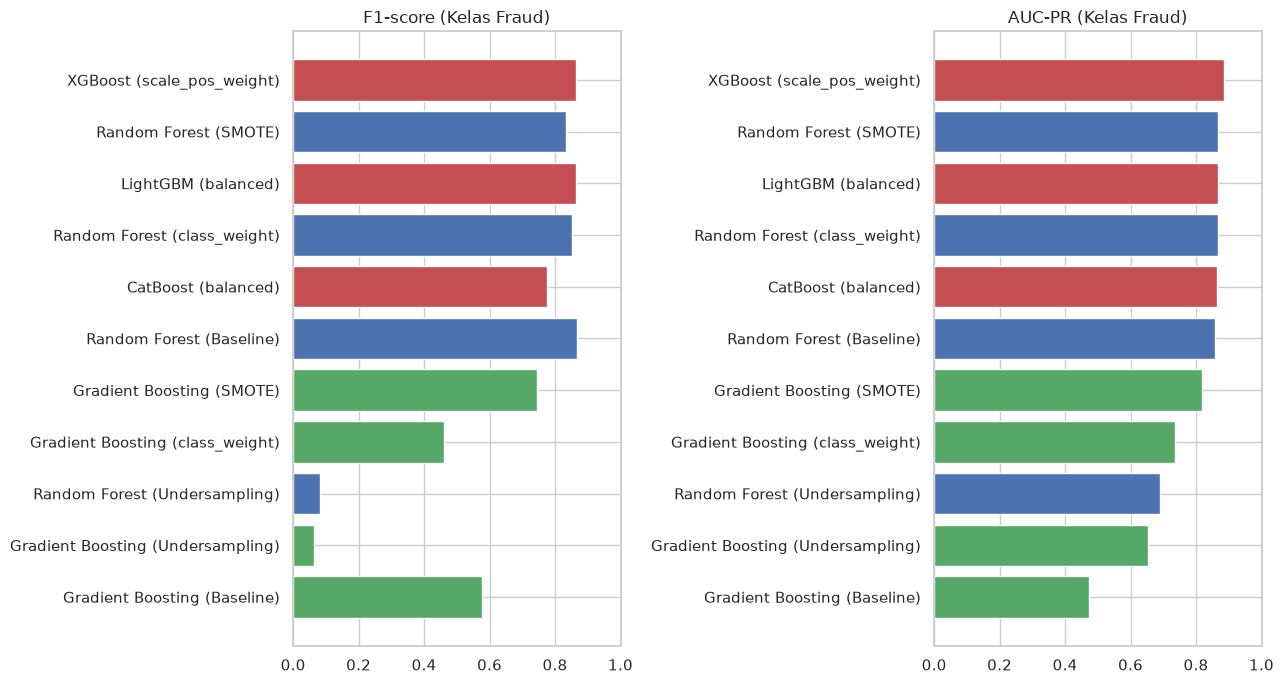

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7))

order = results_df["AUC-PR"].sort_values().index
colors = ["#4C72B0" if "Random Forest" in m else ("#55A868" if "Gradient Boosting" in m else "#C44E52") for m in order]

axes[0].barh(order, results_df.loc[order, "F1"], color=colors)
axes[0].set_title("F1-score (Kelas Fraud)")
axes[0].set_xlim(0, 1)

axes[1].barh(order, results_df.loc[order, "AUC-PR"], color=colors)
axes[1].set_title("AUC-PR (Kelas Fraud)")
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig(os.path.join(SRC, "metric_comparison.png"), dpi=150)
plt.show()

Hasilnya menunjukkan beberapa pola yang penting.

Pada keluarga _ensemble_ inti, Random Forest bersifat jauh lebih tahan terhadap ketidakseimbangan kelas dibanding Gradient Boosting. Bahkan pada konfigurasi baseline, Random Forest sudah mencapai recall 0,8061 dan AUC-PR 0,8584, sedangkan Gradient Boosting baseline hanya mencapai recall 0,6429 dengan AUC-PR 0,4721. Hal ini karena setiap pohon pada Random Forest dibangun dari sampel _bootstrap_ dengan pemilihan _split_ pada subset fitur acak, sehingga kelas minoritas tetap sering terwakili pada simpul-simppul pohon. Sebaliknya, pada Gradient Boosting setiap pohon baru berfokus memperbaiki sisa kesalahan yang didominasi kelas mayoritas.

Setelah penanganan _imbalance_, performa Gradient Boosting melonjak tajam: SMOTE menaikkan recall menjadi 0,8776 dan AUC-PR menjadi 0,8172. Hal ini menunjukkan bahwa Gradient Boosting sangat bergantung pada penanganan _imbalance_, sedangkan Random Forest jauh lebih mandiri.

Ketiga _boosting_ modern tampil sangat kuat dan konsisten. XGBoost dengan `scale_pos_weight` menjadi model tunggal terbaik secara AUC-PR, disusul LightGBM dan CatBoost. Ketiganya tidak memerlukan data sintetis karena penanganan _imbalance_ dilakukan melalui bobot gradien internal, sehingga waktu pelatihannya jauh lebih singkat dibanding Random Forest dengan SMOTE.

Undersampling menghasilkan recall tertinggi pada kedua keluarga _ensemble_ inti, tetapi _precision_-nya anjlok. Hal ini wajar karena data latih menyusut drastis, sehingga model kehilangan banyak informasi kelas mayoritas dan menjadi terlalu agresif menandai fraud.

AUC-ROC seluruh model tampak tinggi (0,94--0,98) dan sulit dibedakan, sedangkan AUC-PR menyebar cukup lebar (0,47--0,88). Perbedaan ini menegaskan bahwa AUC-PR jauh lebih mampu membedakan kualitas model pada dataset yang sangat tidak seimbang.

## Confusion Matrix

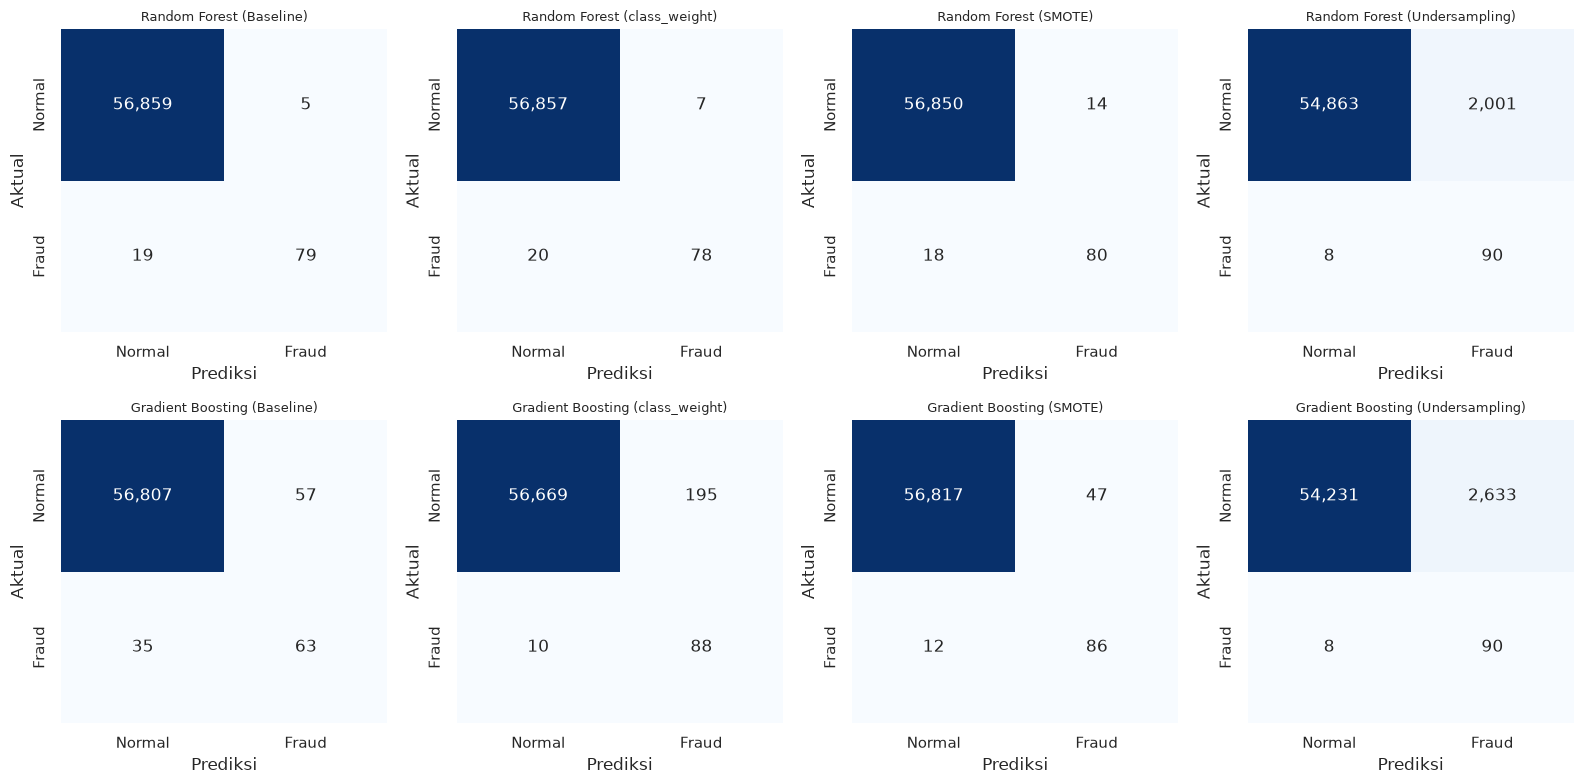

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

ensemble_models = [m for m in results_df.index if "Random Forest" in m or m.startswith("Gradient Boosting")]

for ax, name in zip(axes.ravel(), ensemble_models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(
        cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"],
    )
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

plt.tight_layout()
plt.savefig(os.path.join(SRC, "confusion_matrices.png"), dpi=150)
plt.show()

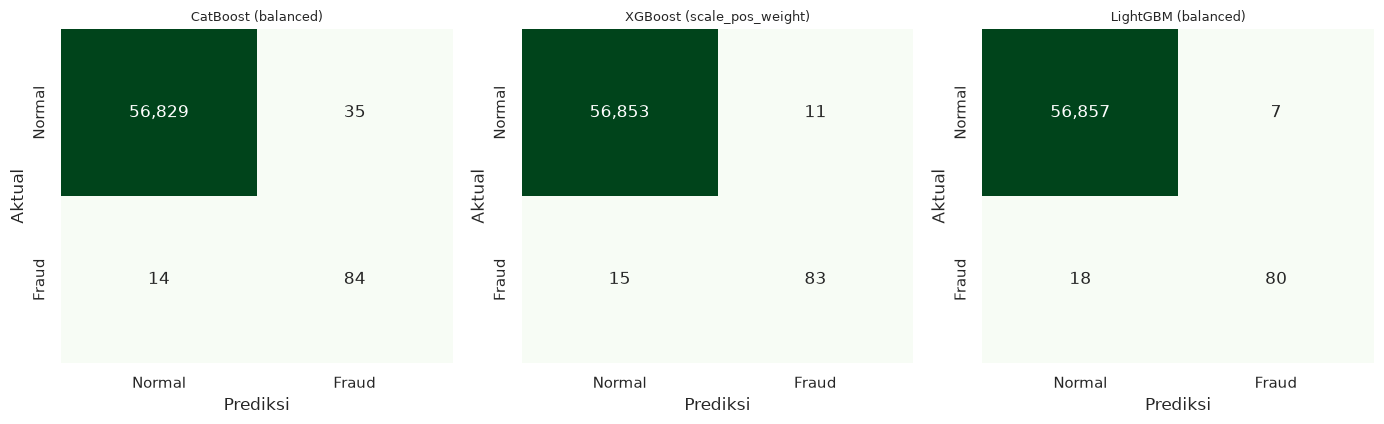

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))

modern_models = ["CatBoost (balanced)", "XGBoost (scale_pos_weight)", "LightGBM (balanced)"]

for ax, name in zip(axes.ravel(), modern_models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(
        cm, annot=True, fmt=",d", cmap="Greens", cbar=False, ax=ax,
        xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"],
    )
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

plt.tight_layout()
plt.savefig(os.path.join(SRC, "confusion_matrices_extra.png"), dpi=150)
plt.show()

Confusion matrix memperjelas _trade-off_ antar pendekatan. Pada Random Forest baseline, terdapat 19 _false negative_ (penipuan yang lolos) dan hanya 5 _false positive_. Setelah SMOTE, _false negative_ turun menjadi 18 dengan _false positive_ 14.

Perbedaan yang jauh lebih mencolok terlihat pada Gradient Boosting. Baseline menghasilkan 35 _false negative_, lalu turun menjadi 10 dengan _class weighting_ dan 12 dengan SMOTE. Penurunan ini menunjukkan bahwa penanganan _imbalance_ pada Gradient Boosting tidak hanya menaikkan metrik secara agregat, tetapi benar-benar mengurangi jumlah penipuan yang lolos.

Undersampling pada kedua keluarga menekan _false negative_ paling rendah, yaitu 8, tetapi konsekuensinya _false positive_ meledak hingga 2.001 sampai 2.633 transaksi normal yang salah ditandai. Hal ini membuat pendekatan tersebut kurang praktis meskipun _recall_-nya tinggi.

Ketiga _boosting_ modern menghasilkan confusion matrix yang seimbang. LightGBM hanya melewatkan 18 penipuan dengan 7 _false positive_, sedangkan XGBoost dan CatBoost masing-masing melewatkan 15 dan 14 penipuan dengan _false positive_ 11 dan 35. Pada kasus deteksi penipuan, _false negative_ jauh lebih merugikan karena penipuan yang tidak terdeteksi menimbulkan kerugian finansial langsung, sedangkan _false positive_ hanya menambah beban verifikasi. Kombinasi yang dicapai ketiga model ini karena itu merupakan hasil yang paling diinginkan.

## Kurva ROC dan Precision-Recall

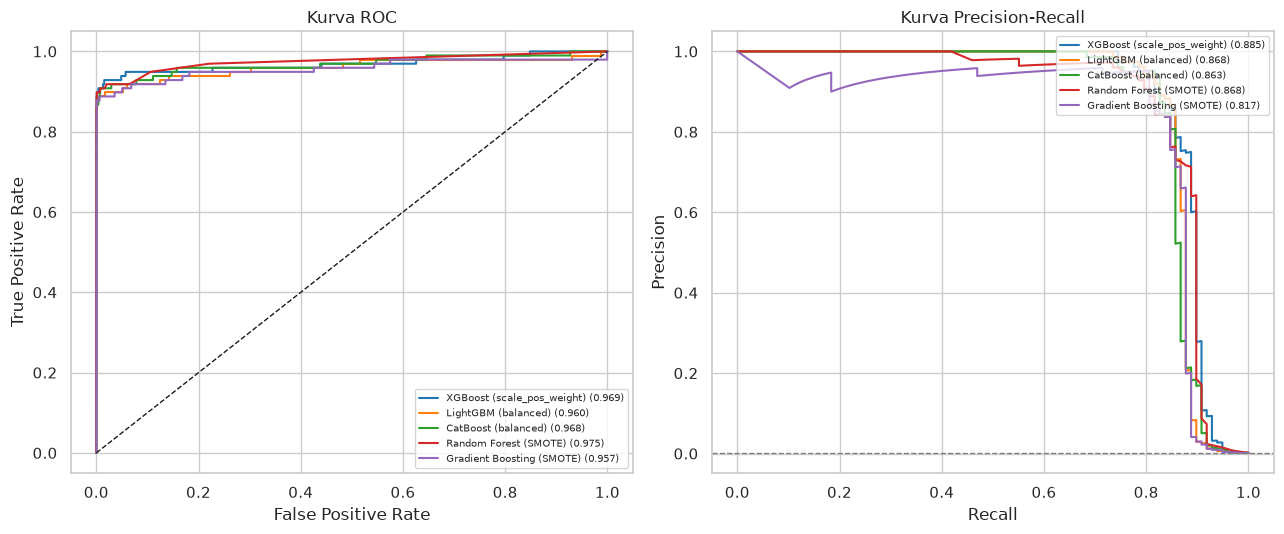

In [27]:
highlight = [
    "XGBoost (scale_pos_weight)",
    "LightGBM (balanced)",
    "CatBoost (balanced)",
    "Random Forest (SMOTE)",
    "Gradient Boosting (SMOTE)",
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

palette = sns.color_palette("tab10", len(highlight))

for color, name in zip(palette, highlight):
    proba = curves[name]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, color=color, label=f"{name} ({roc_auc_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Kurva ROC")
axes[0].legend(fontsize=7, loc="lower right")

for color, name in zip(palette, highlight):
    proba = curves[name]
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, color=color, label=f"{name} ({average_precision_score(y_test, proba):.3f})")

axes[1].axhline(y_test.mean(), color="gray", ls="--", lw=1)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Kurva Precision-Recall")
axes[1].legend(fontsize=7, loc="upper right")

plt.tight_layout()
plt.savefig(os.path.join(SRC, "roc_pr_curves.png"), dpi=150)
plt.show()

Kurva ROC menunjukkan hampir seluruh model memiliki AUC-ROC di atas 0,94, sehingga kurva tampak berdekatan dan sulit dibedakan. Hal ini merupakan konsekuensi dari dominasi kelas mayoritas, di mana _true negative_ yang sangat banyak membuat _false positive rate_ tetap rendah sehingga kurva ROC cenderung bergerak mendekati sudut kiri atas.

Kurva Precision-Recall jauh lebih informatif untuk dataset tidak seimbang. Garis putus-putus merepresentasikan performa model acak, yaitu sebesar prevalensi kelas fraud (0,0017). Di sini pemisahan antar model menjadi jelas: XGBoost dan LightGBM berada paling atas, diikuti CatBoost dan Random Forest, sedangkan Gradient Boosting baseline berada jauh di bawah.

Bentuk kurva ketiga _boosting_ modern juga lebih stabil pada area _recall_ tinggi dibanding Random Forest. Hal ini menunjukkan bahwa selain lebih cepat dilatih, ketiganya menghasilkan peringkat probabilitas yang lebih tajam pada transaksi yang paling mencurigakan.

## Mengapa Accuracy Tidak Cukup

In [28]:
dummy_acc = (y_test == 0).mean()
best_single = results_df["AUC-PR"].idxmax()

pd.DataFrame({
    "Model": ["Prediksi selalu Normal", best_single],
    "Accuracy": [dummy_acc, (preds[best_single] == y_test).mean()],
    "Recall (Fraud)": [0.0, recall_score(y_test, preds[best_single])],
    "F1 (Fraud)": [0.0, f1_score(y_test, preds[best_single])],
}).round(4)

,Model,Accuracy,Recall (Fraud),F1 (Fraud)
0,Prediksi selalu Normal,0.9983,0.0000,0.0000
1,XGBoost (scale_pos_weight),0.9995,0.8469,0.8646


Model yang selalu memprediksi kelas normal memperoleh akurasi 0,9983. Angka ini terlihat sangat baik, tetapi model tersebut sama sekali tidak berguna karena tidak mampu mendeteksi satu pun transaksi penipuan (_recall_ = 0).

Akurasi mengukur proporsi keseluruhan prediksi yang benar, sehingga setiap transaksi normal yang diprediksi benar menyumbang nilai akurasi yang sama besarnya dengan transaksi penipuan. Ketika kelas mayoritas mendominasi 99,8% data, akurasi menjadi tidak sensitif terhadap kesalahan pada kelas minoritas. Padahal pada kasus deteksi penipuan, kelas minoritas justru merupakan kelas yang paling penting untuk dikenali.

Oleh karena itu, metrik yang lebih sesuai adalah _precision_, _recall_, F1-score, dan AUC-PR yang berfokus pada performa pada kelas minoritas. AUC-ROC tetap dapat dilaporkan, tetapi harus dibaca dengan hati-hati karena dapat memberikan kesan performa yang terlalu optimistis pada data yang sangat tidak seimbang.

# Feature Importance

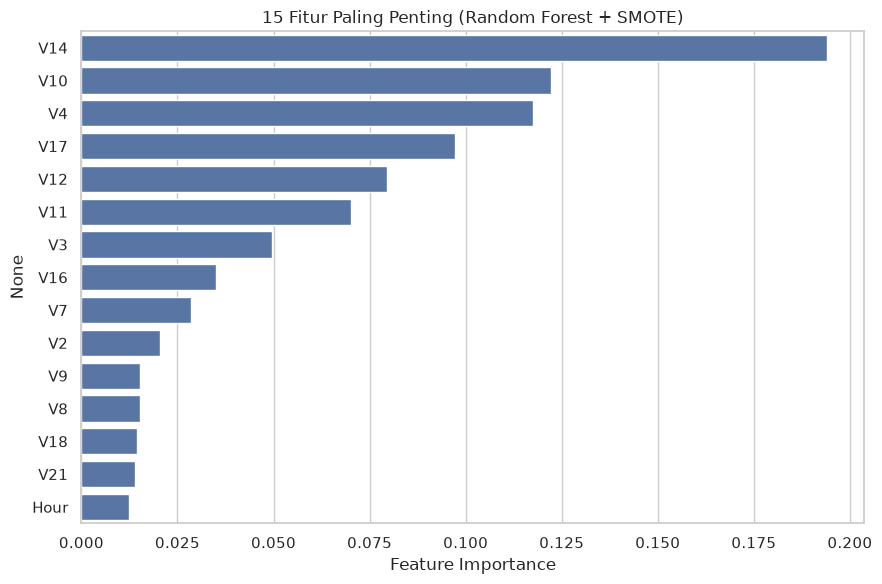

In [29]:
rf = fitted["Random Forest (SMOTE)"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=importance.values, y=importance.index, ax=ax)
ax.set_title("15 Fitur Paling Penting (Random Forest + SMOTE)")
ax.set_xlabel("Feature Importance")

plt.tight_layout()
plt.savefig(os.path.join(SRC, "feature_importance.png"), dpi=150)
plt.show()

Fitur yang paling berpengaruh pada model didominasi oleh komponen PCA tertentu. `V14` menjadi fitur terpenting dengan kontribusi mendekati 0,20, diikuti `V10`, `V4`, `V17`, dan `V12`. Urutan ini konsisten dengan hasil analisis korelasi sebelumnya, di mana `V14` dan `V17` berkorelasi negatif kuat terhadap kelas fraud, sedangkan `V4` dan `V11` berkorelasi positif. Fitur turunan `Hour` juga masuk ke dalam 15 fitur teratas, sedangkan `Amount_scaled` tidak muncul sehingga kontribusinya relatif kecil.

Temuan ini menegaskan bahwa pola penipuan lebih tercermin pada kombinasi pola tersembunyi dalam `V1`--`V28` dibandingkan pada nilai transaksi itu sendiri.

# Threshold Tuning

Model: XGBoost (scale_pos_weight)
Threshold default 0.50 -> F1 = 0.8646
Threshold optimal 0.9376 -> F1 = 0.8743


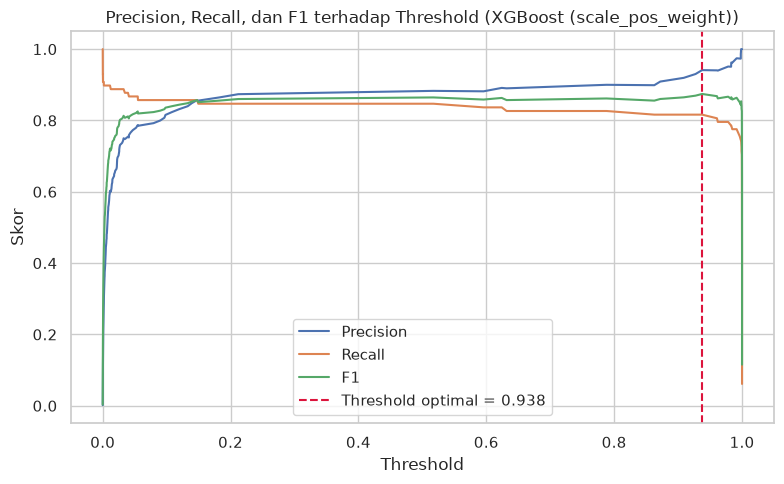

In [30]:
best_name = results_df["AUC-PR"].idxmax()
best_score = curves[best_name]

prec, rec, thr = precision_recall_curve(y_test, best_score)
f1_scores = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
best_idx = int(np.argmax(f1_scores))
best_thr = thr[min(best_idx, len(thr) - 1)]

print(f"Model: {best_name}")
print(f"Threshold default 0.50 -> F1 = {f1_score(y_test, (best_score >= 0.5).astype(int)):.4f}")
print(f"Threshold optimal {best_thr:.4f} -> F1 = {f1_scores[best_idx]:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thr, prec[:-1], label="Precision")
ax.plot(thr, rec[:-1], label="Recall")
ax.plot(thr, f1_scores[:-1], label="F1")
ax.axvline(best_thr, color="crimson", ls="--", label=f"Threshold optimal = {best_thr:.3f}")
ax.set_xlabel("Threshold")
ax.set_ylabel("Skor")
ax.set_title(f"Precision, Recall, dan F1 terhadap Threshold ({best_name})")
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(SRC, "threshold_tuning.png"), dpi=150)
plt.show()

Ambang batas keputusan secara langsung mempengaruhi keseimbangan antara _precision_ dan _recall_. Pada model terbaik, yaitu XGBoost dengan `scale_pos_weight`, F1 meningkat dari 0,8646 pada threshold default 0,5 menjadi 0,8743 pada threshold optimal 0,9376. Threshold yang lebih tinggi membuat model hanya menandai transaksi yang probabilitasnya sangat tinggi sebagai penipuan, sehingga _precision_ naik.

Sebaliknya, menurunkan threshold akan menandai lebih banyak transaksi sebagai penipuan sehingga _recall_ meningkat, tetapi _precision_ menurun. Pemilihan threshold optimal bergantung pada preferensi risiko: apabila biaya kehilangan penipuan jauh lebih besar daripada biaya pemeriksaan transaksi normal, threshold yang menghasilkan _recall_ tinggi lebih disarankan.

# Kesimpulan

Berdasarkan hasil pemodelan, terdapat beberapa temuan utama:

1. Dataset _Credit Card Fraud Detection_ memiliki distribusi kelas yang sangat tidak seimbang, dengan hanya 0,1727% transaksi berupa penipuan (rasio sekitar 578:1).
2. Ketahanan model _ensemble_ terhadap _imbalance_ berbeda antar algoritma. Random Forest tetap kompetitif bahkan pada konfigurasi baseline (recall 0,8061; AUC-PR 0,8584), sedangkan Gradient Boosting baseline sangat lemah (recall 0,6429; AUC-PR 0,4721). Hal ini menunjukkan bahwa pemilihan algoritma _ensemble_ sama pentingnya dengan teknik resampling yang digunakan.
3. Penerapan SMOTE, _undersampling_, dan _class weighting_ meningkatkan kemampuan Gradient Boosting secara drastis. SMOTE menaikkan _recall_ menjadi 0,8776 dan AUC-PR menjadi 0,8172, sedangkan _class weighting_ menghasilkan _recall_ 0,8980.
4. Undersampling menghasilkan _recall_ tertinggi (0,9184) tetapi dengan _precision_ yang sangat rendah (0,0430) karena membuang terlalu banyak data kelas mayoritas. Pendekatan ini kurang cocok ketika ukuran data sudah besar.
5. Tiga implementasi _boosting_ modern tampil paling kuat dan konsisten. XGBoost dengan `scale_pos_weight` menjadi model tunggal terbaik secara AUC-PR (0,8847), sedangkan LightGBM unggul pada F1 (0,8649) dan CatBoost mencapai recall 0,8571. Ketiganya menangani _imbalance_ melalui pembobotan gradien internal sehingga tidak memerlukan data sintetis, dan menghasilkan _false negative_ rendah tanpa ledakan _false positive_.
6. AUC-PR lebih representatif dibanding AUC-ROC untuk dataset yang sangat tidak seimbang, karena AUC-ROC seluruh model tampak tinggi dan sulit dibedakan.
7. Akurasi tidak dapat dijadikan metrik utama karena didominasi kelas mayoritas; model yang selalu memprediksi kelas normal tetap memperoleh akurasi 0,9983 meskipun _recall_-nya nol.
8. Penyesuaian threshold keputusan dapat meningkatkan F1 model terbaik dari 0,8646 menjadi 0,8743, sehingga pemilihan threshold perlu disesuaikan dengan preferensi risiko.

# Referensi

- Breiman, L. (2001). _Random Forests_. Machine Learning, 45(1), 5--32.
- Chen, T., & Guestrin, C. (2016). _XGBoost: A Scalable Tree Boosting System_. KDD.
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). _SMOTE: Synthetic Minority Over-sampling Technique_. Journal of Artificial Intelligence Research, 16, 321--357.
- He, H., & Garcia, E. A. (2009). _Learning from Imbalanced Data_. IEEE Transactions on Knowledge and Data Engineering, 21(9), 1263--1284.
- Ke, G., et al. (2017). _LightGBM: A Highly Efficient Gradient Boosting Decision Tree_. NeurIPS.
- Pedregosa, F., et al. (2011). _Scikit-learn: Machine Learning in Python_. Journal of Machine Learning Research, 12, 2825--2830.
- Prokhorenkova, L., et al. (2018). _CatBoost: Unbiased Boosting with Categorical Features_. NeurIPS.